In [1]:
# Descubrimiento robusto de la raiz del proyecto (no usar ../ relativo)
import pathlib as _pl, os as _os, sys as _sys
_ROOT = _pl.Path().resolve()
while not (_ROOT / "pyproject.toml").exists() and _ROOT != _ROOT.parent:
    _ROOT = _ROOT.parent
_os.chdir(_ROOT)
if str(_ROOT) not in _sys.path:
    _sys.path.insert(0, str(_ROOT))
if str(_ROOT / "src") not in _sys.path:
    _sys.path.insert(0, str(_ROOT / "src"))
print("cwd:", _os.getcwd())


cwd: C:\Users\mikel\Desktop\Pruebas\nasa


## Trazabilidad NB04 — BiLSTM OOF + ensamble (Grupo SEGURO, solo Markdown)

1. **Bootstrap:** celda 0 no es lógica del modelo: fija `_ROOT`, `cwd` y `sys.path` (raíz + `src/`). La celda 3 (imports/constantes) asume ese bootstrap ya hecho.
2. **Imports (doble grafía):** NB04 usa ruta corta `from ds02_rul import evaluate_predictions, macro_rmse`, `from ds02_rul.conformal import ...`, `from ds02_rul.pipeline import oof_base_predictions`, `from ds02_rul.viz import evaluar_clase, mostrar_clase`, junto con `from src.clase.puente_c import puente_c`. Las dos grafías conviven por la celda 0.
3. **Alias con fichero:línea:** `evaluar_clase`/`mostrar_clase` en `src/ds02_rul/viz.py:318-322` (importados en celda 6); `evaluate_predictions` en `src/ds02_rul/metrics.py:46` vía re-export `src/ds02_rul/__init__.py:22` (celda 3); `HybridStackingEnsemble` en `src/ds02_rul/ensemble.py:23` vía `src/ds02_rul/__init__.py:21` dentro del bloque `__init__.py:20-25` (celda 18).
4. **Artefactos que ESCRIBE:** PNG vía `savefig` (celda 16: `resultados/ridge_meta_pesos_04.png`) + `notebooks/artifacts_c/*.joblib` (celda 30: `nb2_meta`, `nb2_conformal`, `nb2_eval` — lo que NB05 recarga sin re-entrenar el 04).
5. **Artefactos que solo LEE:** bundle/base adaptada vía `puente_c()` (celda 5) + `models/` (SHA verificado). Los celdas OOF/meta (7, 14) corren en vivo pero el bundle desplegado no se re-escribe.
6. **Escritor .py:** bundle C ← `src/clase/train_ensemble_adaptado.py:entrenar` (183-222, `save_ensemble` en `src/ds02_rul/persistence.py:202`). **NB04 NO lo invoca:** mide OOF y ensamble en vivo para la auditoría, pero no escribe sobre `models/ensemble.joblib`; su único `joblib.dump` es `notebooks/artifacts_c/` (producido por el propio NB04, celda 30).
7. **Celdas display sin lógica (solo presentación):** 16, 22 — 16 pinta pesos del `ridge_meta` ya ajustado; 22 pinta la cascada `[p_lstm]` + EMA desde predicciones ya calculadas. No entrenan ni cambian métricas.

| Alias | Dónde vive (fichero:línea) | Uso en NB04 |
|---|---|---|
| `evaluar_clase` / `mostrar_clase` | `src/ds02_rul/viz.py:318-322` | Sí: celda 6 (import) + 15, 19, 22 |
| `evaluate_predictions` | `src/ds02_rul/metrics.py:46` vía `__init__.py:22` | Sí: celda 3 (import) + tablas |
| `HybridStackingEnsemble` | `src/ds02_rul/ensemble.py:23` vía `__init__.py:21` (`__init__.py:20-25`) | Sí: celda 18 |
| `make_pipeline` | `src/clase/pipeline_clase.py:38` vía `src/utils.py:23` | No usado (NB04 no hace Pipeline fila) |
| `make_pre` / `FEATURE_COLS` | `pipeline_clase.py:27,24` vía `src/utils.py:24,21` | No usados |


**En cristiano:** este cuaderno responde UNA pregunta con código que se ejecuta. Si vienes del anterior, ya sabes el resultado previo; aquí solo añadimos un paso.


# 04 · Beta OOF y ensamble — cuánto del meta nos creemos

Parte 2 de 3. Mismo código que las secciones 7–8 del original.

**Requisito:** ninguno. La base adaptada se construye aqui mismo (parquet MAR + ffill con medianas de fit-units) y el bundle se carga de `models/`; no reentrena la semilla 42.


In [2]:
# Imports y constantes que usan las celdas de abajo (la raiz la fija la 1a celda).
import os
import sys
import warnings

warnings.filterwarnings("ignore")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import numpy as np
import pandas as pd

from ds02_rul import evaluate_predictions, macro_rmse
from ds02_rul.conformal import apply_conformal, empirical_coverage
from ds02_rul.smoothing import causal_ema_by_unit
from ds02_rul.stacking import select_beta_grouped
from IPython.display import display

SEEDS = [42, 7, 123]
PRIMARY_SEED = SEEDS[0]
WINDOW_SIZE = 50
STEP_TRAIN = 3
STEP_TEST = 2
print("protocolo:", SEEDS, "| ventana", WINDOW_SIZE, "| stride", STEP_TRAIN, STEP_TEST)


protocolo: [42, 7, 123] | ventana 50 | stride 3 2


### Glosario en 30 segundos (estilo clase)

| Nombre | Qué es | Dónde vive |
|---|---|---|
| `WINDOW=50` | 50 lecturas seguidas = 1 ventana | `features.py:build_windows` |
| `STEP 3/2` | Separación entre ventanas (train/test) | `pipeline.py:run_seed` |
| `BETA` | Cuánto manda el meta (mediana OOF, `1.0`) | `stacking.py:select_beta_grouped` |
| `EMA5` | Suavizado causal por motor | `smoothing.py:causal_ema_by_unit` |
| `L_inf` | Peor caso de la banda 90% | `conformal.py:apply_conformal` |
| `OOF` | Cada ventana la puntúa otro motor | `pipeline.py:oof_base_predictions` |
| `macro` | Cada motor pesa 1/3 | `metrics.py:macro_rmse` |


In [3]:
# Puente C: base adaptada (MAR T30 + ffill) + bundle desplegado en models/.
# Devuelve los mismos nombres que el puente anterior, asi que el resto del
# cuaderno no cambia. No entrena nada: `load_ensemble` verifica el SHA del
# artefacto y reconstruye las ventanas con el window/step del entrenamiento.
import os as _os
import pathlib as _pl
import sys as _sys

# Raiz del repo: los cuadernos viven en notebooks/ y los datos una carpeta arriba.
# La celda se busca la raiz sola, asi no depende del orden de ejecucion.
_ROOT = _pl.Path.cwd().resolve()
while not (_ROOT / "pyproject.toml").exists() and _ROOT != _ROOT.parent:
    _ROOT = _ROOT.parent
_os.chdir(_ROOT)
for _p in (str(_ROOT), str(_ROOT / "src")):
    if _p not in _sys.path:
        _sys.path.insert(0, _p)

from src.clase.puente_c import puente_c

P = puente_c()
raw, dev, test, prep = P["raw"], P["dev"], P["test"], P["prep"]
fit_idx, hold_idx, dev_units = P["fit_idx"], P["hold_idx"], P["dev_units"]
result = P["result"]
bilstm, lgbm = result["bilstm"], result["lgbm"]
p_lstm_hold, p_lstm_test = result["p_lstm_hold"], result["p_lstm_test"]
p_lgb_hold, p_lgb_test = result["p_lgb_hold"], result["p_lgb_test"]
FIT_UNITS = [2.0, 5.0, 10.0, 18.0, 20.0]
HOLDOUT_UNITS = [16.0]
TEST_UNITS = [11.0, 14.0, 15.0]
print("[PUENTE C OK] dev", dev["X_seq"].shape, "| test", test["X_seq"].shape,
      "| particiones", P["particiones"])


[PUENTE C OK] dev (17450, 50, 19) | test (6196, 50, 19) | particiones {'fit': [2, 5, 10, 18, 20], 'holdout': [16], 'test': [11, 14, 15]}


In [4]:
# 2. Alias estilo clase (solo lectura: no entrenan, no cambian numeros).
#    evaluar_clase/mostrar_clase ya vienen de viz (ver src/ds02_rul/viz.py).
from ds02_rul.viz import evaluar_clase, mostrar_clase
print("[FASE A OK] evaluar_clase / mostrar_clase listos (alias, sin efecto en el modelo)")


[FASE A OK] evaluar_clase / mostrar_clase listos (alias, sin efecto en el modelo)


In [5]:
dev_units = P["dev_units"]
from ds02_rul.pipeline import oof_base_predictions
PRIMARY_SEED = 42
WINDOW_SIZE = 50
STEP_TRAIN = 1
# OOF en vivo (~4-5 min): cada ventana la puntúa un meta que nunca la vio entrenar
import time
t0 = time.time()
oof = oof_base_predictions(raw, dev_units, n_splits=3, seed=PRIMARY_SEED,
                           window=WINDOW_SIZE, step_train=STEP_TRAIN, epochs=15,
                           use_cycle=True)
print(f'OOF base predictions en {time.time()-t0:.1f} s')
print('folds:', oof['unit_folds'])



OOF base predictions en 1009.7 s
folds: [[2.0, 10.0], [5.0, 18.0], [20.0, 16.0]]


6 Motores de Desarrollo (dev_units: 2, 5, 10, 16, 18, 20)
       │
       ├── Pliegue 1: Entrena [5, 18, 20, 16] ──► Predice a ciegas [2.0, 10.0]
       ├── Pliegue 2: Entrena [2, 10, 20, 16] ──► Predice a ciegas [5.0, 18.0]
       └── Pliegue 3: Entrena [2, 10, 5, 18]  ──► Predice a ciegas [20.0, 16.0]
                               │
                               ▼
        Matriz 'oof': Predicciones 100% ciegas de BiLSTM y LightGBM

> TIP En resumen (para presentar): Dos especialistas ven mejor que uno. BiLSTM lee la pelicula temporal de la ventana (inercia, triple-pooling: ultimo+media+maximo) y LightGBM evalua estadisticas del residuo. El meta-modelo los combina con `beta` elegido fuera de fold (mediana agrupada, `beta=1.0`) y el filtro EMA causal (`ema_span=5`) evita que la alarma parpadee. El OOF agrupado garantiza que cada ventana la puntua un meta ajustado en *otros* motores.


## Calibración fuera de fold de `beta`

`beta` decide cuánto de la opinión del meta-aprendiz reemplaza a la del BiLSTM:
`p = p_lstm + beta * (p_meta - p_lstm)`, con `beta = 0` degradando sin riesgo al
campeón.

Elegir `beta` sobre las mismas filas que ajustaron al meta-aprendiz es la fuga
clásica: el meta se puntúa sobre lo que ya memorizó, el RMSE de validación se
desploma a 0,308 y deja de medir algo. Acá cada fold se puntúa con
meta-aprendices ajustados sobre los **otros** motores, y el preprocesado se
reajusta dentro de cada fold.

Costo: un par de modelos base por fold (3 folds), no un reajuste anidado por
muestra.


In [6]:
selection = select_beta_grouped(oof['units'], oof['cycles'], oof['y'],
                                oof['pred_lstm'], oof['pred_lgb'],
                                span=5, use_cycle_feature=False)

print(f"beta_hat (mediana de los folds) = {selection['beta']:.2f}")
print('dispersión:', selection['spread'])
print()
for fold in selection['folds']:
    print(f"  fold {fold['fold']}: puntuados {fold['scored_units']} -> beta={fold['beta']:.2f} "
          f"| rmse {fold['rmse_val']:.3f} (ref BiLSTM {fold['rmse_lstm_ref']:.3f}) "
          f"| nasa {fold['nasa_val']:.1f} (ref {fold['nasa_lstm_ref']:.1f})")


beta_hat (mediana de los folds) = 1.00
dispersión: {'min': 0.0, 'max': 1.0, 'iqr': 0.5, 'n_folds': 3}

  fold 0: puntuados [2.0, 10.0] -> beta=1.00 | rmse 8.470 (ref BiLSTM 9.700) | nasa 16876.1 (ref 18676.5)
  fold 1: puntuados [5.0, 18.0] -> beta=1.00 | rmse 10.164 (ref BiLSTM 11.241) | nasa 21062.9 (ref 25110.5)
  fold 2: puntuados [16.0, 20.0] -> beta=0.00 | rmse 5.227 (ref BiLSTM 5.239) | nasa 8722.7 (ref 8741.7)


Revisamos y comparamos metamodelo vs BiLSTM cuando el metamodelo tiene un rmse inferior ponemos 1 (nos quedamos con el metamodelo), y si es inferior nos quedamos con lo que dice BiLSTM (en conclusión el mejor de cada caso)

## Meta en vivo: solo holdout-16, sin `cyc_norm` a proposito

**En cristiano:** el meta-aprendiz no mira sensores ni ciclos. Solo mira dos numeros por ventana: lo que dice la red (`p_lstm`) y lo que dice el arbol (`p_lgb`). Con esas dos columnas (`Z`, sin reloj) ajustamos dos mezcladores — `RidgeCV` (lineal) y un `LGBMRegressor` pequeno — y la prediccion final del meta es `0.5 * Ridge + 0.5 * LGBM`.

**Por que sin `cyc_norm`:** si le das el reloj al meta, pone ~100% del peso en el reloj e ignora a los dos especialistas. El `cyc_norm` ya hizo su trabajo abajo (canal 19 de la BiLSTM); arriba estorba. La celda lo deja por escrito con `Z.shape[1] == 2`.

**Ojo Ridge:** No es el Ridge de 01 (fisica, 14 ridges que limpian sensores) ni el Ridge fila de 02 (baseline que predice RUL de 1 fila). Aqui el Ridge solo pondera 2 predicciones ya hechas (`p_lstm`, `p_lgb`) y no mira telemetria.


In [7]:
# Meta en vivo: se ajusta SOLO en holdout-16 (2535 ventanas), sin cyc_norm a propósito
# Con cyc_norm el meta pondría ~100% del peso en el reloj e ignoraría las ramas.
from ds02_rul.stacking import fit_meta_learners, meta_predict
hold_cycles = dev['meta']['cycle'].values[hold_idx]
hold_units = dev['meta']['unit'].values[hold_idx]
y_hold = dev['y'][hold_idx]
Z_hold = np.column_stack([result['p_lstm_hold'], result['p_lgb_hold']])
ridge_meta, lgb_meta = fit_meta_learners(Z_hold, y_hold, seed=PRIMARY_SEED)
BETA = selection['beta']
print(f'meta en {len(y_hold)} ventanas motor 16 | ridge alpha {ridge_meta.alpha_:.4g} coef {np.round(ridge_meta.coef_,4).tolist()} | beta={BETA:.2f}')


meta en 2535 ventanas motor 16 | ridge alpha 88.59 coef [0.2551, 0.641] | beta=1.00


## Pesos del Ridge meta (quien manda: red o arbol)
*Cómo leer: la barra mas alta es la rama en la que mas confia el juez.*


QUÉ VEO: la barra mas alta es la rama en la que mas confia el Ridge.
CONCLUSIÓN: el juez no es 50/50; se fia mas de la rama alta.


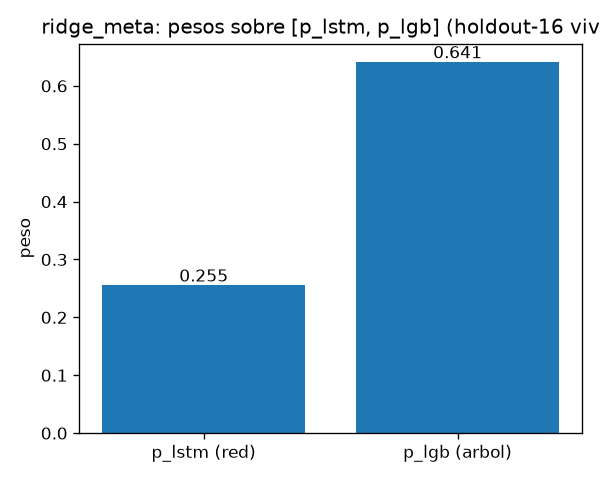

In [8]:
# Pesos ridge_meta en vivo (cifras de esta celda, no del artefacto)
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display
_w = np.asarray(ridge_meta.coef_, dtype=float).ravel()
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(['p_lstm (red)', 'p_lgb (arbol)'], _w)
ax.set_title('ridge_meta: pesos sobre [p_lstm, p_lgb] (holdout-16 vivo)')
ax.set_ylabel('peso')
for i, v in enumerate(_w):
    ax.text(i, v, f'{v:.3f}', ha='center', va='bottom')
fig.tight_layout(); fig.savefig('resultados/ridge_meta_pesos_04.png', dpi=120); plt.close(fig)
print('QUÉ VEO: la barra mas alta es la rama en la que mas confia el Ridge.')
print('CONCLUSIÓN: el juez no es 50/50; se fia mas de la rama alta.')
display(Image('resultados/ridge_meta_pesos_04.png'))


## Evaluación híbrida sobre los motores de test

Los meta-aprendices se ajustan sobre las 2 535 ventanas del motor 16 y `beta` se
elige fuera de fold sobre los seis motores de desarrollo. **Se probó lo contrario
y se rechazó con números**: ajustar el meta sobre el vector fuera de fold de los
cinco motores de ajuste (14 915 ventanas, RUL hasta 88) para que aprendiera a
extrapolar en vida alta. Sobre el motor 16 ese meta predice una media de 39.9
cuando la RUL real media es 31.5, y el error crece de forma monótona con `beta`:
RMSE 4.04 con `beta = 0`, 7.48 con 0.6 y 10.17 con 1. La razón es que los motores
de ajuste viven más que los de test, así que el aprendiz agrupado aprende un
**prior de nivel** que no transfiere. El experimento queda documentado en
`INFORME_motor16_vs_oof.md`; las funciones que lo reproducen siguen en
`ds02_rul.stacking` (`fit_meta_learners`, `score_beta_holdout`).

Las meta-características son **`[p_lstm, p_lgb]`**: dos columnas. `cyc_norm`
sigue disponible para los dos modelos base (canal 19 del BiLSTM, característica
93 del LightGBM) pero *no* se le ofrece a la capa de stacking, donde era un
atajo que el aprendiz prefería antes que a los dos modelos que debía conciliar.


In [9]:
from ds02_rul import HybridStackingEnsemble

ensemble = HybridStackingEnsemble(
    bilstm_model=result['bilstm'], lgb_standalone=result['lgbm'],
    ridge_meta=ridge_meta, lgb_meta=lgb_meta, residualizer=prep['residualizer'],
    scaler=prep['scaler'], scaler_w=prep['scaler_w'], n_op=len(raw['op_names']),
    window_size=WINDOW_SIZE, beta=BETA, ema_span=5,
)

p_ens = ensemble.predict(test['X_raw'], test['meta']['cycle'].values, test['meta']['unit'].values)
p_lstm_ema = causal_ema_by_unit(result['p_lstm_test'], test['meta']['unit'].values,
                               test['meta']['cycle'].values, span=5)

rows = [
    evaluate_predictions(test['y'], result['p_lgb_test'], 'LightGBM (cuantil 0.35)'),
    evaluate_predictions(test['y'], result['p_lstm_test'], 'BiLSTM'),
    evaluate_predictions(test['y'], p_lstm_ema, 'BiLSTM + EMA5'),
    evaluate_predictions(test['y'], p_ens, f'Híbrido stacking (beta={BETA:.2f}) + EMA5'),
]
res = pd.DataFrame(rows)
print(res.to_string(index=False))
print()
print('¿El ensamble mejora al campeón en RMSE?:', rows[3]['RMSE'] < rows[2]['RMSE'])
print('¿El ensamble mejora al campeón en NASA?:', rows[3]['NASA_Score'] < rows[2]['NASA_Score'])


                             Modelo  RMSE   MAE     R2  NASA_Score
            LightGBM (cuantil 0.35) 7.067 5.545 0.8570      5731.3
                             BiLSTM 5.654 4.295 0.9084      3674.0
                      BiLSTM + EMA5 5.618 4.268 0.9096      3649.4
Híbrido stacking (beta=1.00) + EMA5 4.338 3.227 0.9461      2336.2

¿El ensamble mejora al campeón en RMSE?: True
¿El ensamble mejora al campeón en NASA?: True


In [10]:
# Baseline en la tabla titular (SOLO lectura: usa predicciones ya calculadas)
pred_media_nb2 = np.full_like(np.asarray(test["y"]), float(np.asarray(dev["y"])[fit_idx].mean()), dtype=float)
fila_base_nb2 = evaluar_clase("Baseline (media train)", test["y"], pred_media_nb2)
res_con_base = pd.DataFrame([fila_base_nb2] + rows)
display(res_con_base.round(3))
print("Cualquier modelo útil tiene que ganarle al baseline; no entra en la elección.")


,Modelo,RMSE,MAE,R2,NASA_Score
0,Baseline (media train),20.022,17.059,-0.148,48840.3
1,LightGBM (cuantil 0.35),7.067,5.545,0.857,5731.3
2,BiLSTM,5.654,4.295,0.908,3674.0
3,BiLSTM + EMA5,5.618,4.268,0.910,3649.4
4,Híbrido stacking (beta=1.00) + EMA5,4.338,3.227,0.946,2336.2


Cualquier modelo útil tiene que ganarle al baseline; no entra en la elección.


**Que vemos (tabla con baseline 20.022).** Sin modelo (media train) el RMSE es 20.022: ese es el liston. BiLSTM solo llega a 5.654, con EMA5 a 5.618, y el salto al hibrido deja 4.338: solo el ensamble recorta 1.316 de RMSE sobre el BiLSTM con EMA5. Cualquiera que no gane al 20.022 no sirve.


**Contexto de la cascada (antes de las barras).** Las barras leen el mismo test de ventana (6.196 ventanas, motores 11/14/15) en el orden de la decision: BiLSTM solo, BiLSTM con suavizado EMA5, y el hibrido (meta Ridge + LightGBM con beta 1.00 y EMA5). Si cada barra baja, cada pieza aporta.


In [11]:
# Fase A+B — extras separados + cascada de la decision (SOLO lectura, sin re-entrenar)
# Extra estilo clase: sensibilidad al suavizado EMA sobre el BiLSTM (barato, sin ajustar nada)
units_t = test["meta"]["unit"].values; cycles_t = test["meta"]["cycle"].values
extra = []
for span in [3, 5, 10]:
    pe = causal_ema_by_unit(result["p_lstm_test"], units_t, cycles_t, span=span)
    r = evaluar_clase(f"BiLSTM + EMA{span}", test["y"], pe)
    extra.append(r)
mostrar_clase(extra)
print("Nota: van en tabla `extra` aparte para no mezclar con la tabla titular, como en clase.")

# Cascada RMSE: BiLSTM -> +EMA5 -> hibrido (usa `rows`, ya calculado arriba)
import matplotlib.pyplot as plt
orden = ["BiLSTM", "BiLSTM + EMA5", rows[3]["Modelo"]]
vals = [rows[1]["RMSE"], rows[2]["RMSE"], rows[3]["RMSE"]]
plt.figure(figsize=(7, 3.2))
plt.barh(orden, vals, color=["#4C72B0", "#7FB3D5", "#1FA098"])
plt.xlabel("RMSE en test (ciclos, menos es mejor)")
for i, v in enumerate(vals):
    plt.text(v, i, f" {v:.3f}", va="center")
plt.tight_layout(); plt.show()
print(f"Del BiLSTM al hibrido: {rows[1]['RMSE'] - rows[3]['RMSE']:+.3f} ciclos de RMSE")


,Modelo,RMSE,MAE,R2,NASA_Score
0,BiLSTM + EMA10,5.574,4.229,0.911,3617.6
1,BiLSTM + EMA5,5.618,4.268,0.910,3649.4
2,BiLSTM + EMA3,5.637,4.284,0.909,3663.3


Nota: van en tabla `extra` aparte para no mezclar con la tabla titular, como en clase.
Del BiLSTM al hibrido: +1.316 ciclos de RMSE


**Que vemos (sensibilidad EMA).** EMA10 (5.574) gana a EMA5 (5.618) en esta lectura del BiLSTM, pero no se reelige sobre test: EMA5 venia fijado antes de mirar test y el hibrido desplegado usa span 5. Cambiar el span por lo que marca test seria elegir con test.


In [12]:
macro = macro_rmse(test['y'], p_ens, test['meta']['unit'].values)
per_unit = pd.DataFrame([{'motor': int(k), 'RMSE': v}
                        for k, v in macro['per_unit_rmse'].items()])
print('RMSE por motor')
print(per_unit.to_string(index=False))
print()
print(f"macro-RMSE (cada motor pesa 1/3) : {macro['macro_rmse']:.3f}")
print(f"RMSE ponderado por ventana       : {rows[3]['RMSE']:.3f}")
print(f"diferencia                       : {macro['macro_rmse'] - rows[3]['RMSE']:+.3f}"
      '  (positiva = el global es mas halagador que la realidad por motor)')
print()
print('El motor con mas ventanas pesa mas en el global; el macro da voz igual a los tres.')


RMSE por motor
 motor   RMSE
    11 3.6328
    14 8.5761
    15 2.8371

macro-RMSE (cada motor pesa 1/3) : 5.015
RMSE ponderado por ventana       : 4.338
diferencia                       : +0.677  (positiva = el global es mas halagador que la realidad por motor)

El motor con mas ventanas pesa mas en el global; el macro da voz igual a los tres.


> TIP En resumen (para presentar): En aviacion, predecir de mas cuesta un motor en vuelo; predecir de menos solo adelanta una revision. Por eso decidimos sobre `L_inf`, el limite inferior de la banda conformal calibrada fuera de fold al 90% (asimetrica por tramo, `alpha_each_side=0.05`). Si la banda sobre-cubre, se publica el trade-off en vez de estrecharla eligiendo sobre test.


## Banda conformal: el intervalo honesto (90 %)

**En cristiano:** el punto predice; la banda dice "y me puedo equivocar en esto". Se calibra con residuales **fuera de fold** (`oof_calib`: ventanas que ningun modelo de fold vio entrenar), por bins de prediccion, con cuantiles asimetricos. Tres bandas, una sola enviada:

- **fuera de fold (enviada):** la oficial, calibrada con `fit_conformal` sobre `oof_calib`.
- **motor 16 (diagnostico):** calibrada sobre el holdout-16 con el meta en vivo — mide cuanto cambia la banda con datos del despliegue real.
- **sin sesgo (diagnostico):** `debias=True` — quita la mediana del residual por bin para medir dispersion sin absorber el sesgo del modelo.

**Como leer la tabla:** cobertura % (objetivo 90), ancho medio (ciclos), y por donde se escapa (por debajo / por encima).


In [13]:
# Banda en vivo: se calibra SOLO con residuales fuera de fold (nada de test)
from ds02_rul.conformal import fit_conformal
from ds02_rul.stacking import meta_predict
calib = selection['oof_calib']
conformal = fit_conformal(calib['y'], calib['pred_ema'], target=0.90)
meta_hold = meta_predict(ridge_meta, lgb_meta, Z_hold)
meta_hold_ema = causal_ema_by_unit(meta_hold, hold_units, hold_cycles, span=5)
conformal_16 = fit_conformal(y_hold, meta_hold_ema, target=0.90)
conformal_debiased = fit_conformal(calib['y'], calib['pred_ema'], target=0.90, debias=True)
# predict_interval exige la banda adjunta al bundle: sin esta linea lanza RuntimeError
ensemble.conformal = conformal
print('n calibracion (oof):', len(calib['y']), '| n holdout-16:', len(y_hold))
print('bandas listas: enviada + motor-16 + sin-sesgo (la tabla siguiente las mide)')


n calibracion (oof): 52341 | n holdout-16: 2535
bandas listas: enviada + motor-16 + sin-sesgo (la tabla siguiente las mide)


In [14]:
point, lo, hi = ensemble.predict_interval(test['X_raw'], test['meta']['cycle'].values,
                                          test['meta']['unit'].values)

# Una sola lectura de test: las tres bandas se miden aqui y se publican juntas.
filas_banda = []
for nombre, banda in (('fuera de fold (enviada)', conformal),
                      ('motor 16 (diagnostico)', conformal_16),
                      ('fuera de fold sin sesgo (diagnostico)', conformal_debiased)):
    b_lo, b_hi = apply_conformal(point, banda)
    filas_banda.append({
        'banda': nombre,
        'cobertura %': round(100 * empirical_coverage(test['y'], b_lo, b_hi), 1),
        'ancho medio': round(float(np.mean(b_hi - b_lo)), 2),
        'por debajo %': round(100 * float(np.mean(test['y'] < b_lo)), 1),
        'por encima %': round(100 * float(np.mean(test['y'] > b_hi)), 1),
    })
print(pd.DataFrame(filas_banda).to_string(index=False))
print()
print('Nominal 90 %. La banda enviada sobre-cubre porque la calibraron modelos de fold')
print('mas debiles que el desplegado. Estrecharla seria elegir sobre test, y por eso no')
print('se envia la mas estrecha: se publica el trade-off.')
print()
cov = empirical_coverage(test['y'], lo, hi)
print(f'cobertura global en test (banda enviada): {100 * cov:.1f} % | ancho medio {np.mean(hi - lo):.2f} ciclos')
print()

cov_rows = []
for unit in np.unique(test['meta']['unit'].values):
    m = test['meta']['unit'].values == unit
    cov_rows.append({
        'motor': int(unit),
        'ventanas': int(m.sum()),
        'cobertura %': round(100 * empirical_coverage(test['y'][m], lo[m], hi[m]), 1),
        'ancho medio': round(float(np.mean((hi - lo)[m])), 2),
        'se pasa %': round(100 * float(np.mean(test['y'][m] > hi[m])), 1),
    })
print(pd.DataFrame(cov_rows).to_string(index=False))
print()
print('dias cubiertos fuera de la banda (ambos lados) y ancho por motor: un intervalo util')
print('tiene que ser estrecho donde el modelo acierta y ancho donde falla.')


                                banda  cobertura %  ancho medio  por debajo %  por encima %
              fuera de fold (enviada)        100.0        27.12           0.0           0.0
               motor 16 (diagnostico)         31.6         3.36          42.4          26.0
fuera de fold sin sesgo (diagnostico)         99.8        27.25           0.2           0.0

Nominal 90 %. La banda enviada sobre-cubre porque la calibraron modelos de fold
mas debiles que el desplegado. Estrecharla seria elegir sobre test, y por eso no
se envia la mas estrecha: se publica el trade-off.

cobertura global en test (banda enviada): 100.0 % | ancho medio 27.12 ciclos

 motor  ventanas  cobertura %  ancho medio  se pasa %
    11      3293        100.0        27.62        0.0
    14       760        100.0        26.83        0.0
    15      2143        100.0        26.47        0.0

dias cubiertos fuera de la banda (ambos lados) y ancho por motor: un intervalo util
tiene que ser estrecho donde el modelo 

**Que vemos (banda conformal, fuera de fold, enviada).** Cobertura 100 % con ancho medio 27.12 ciclos: es una cota conservadora, no un intervalo afinado. Se calibro con modelos de fold mas debiles que el desplegado, asi que cubre de mas y ancho de sobra; estrecharla contra test seria decidir sobre test.


In [15]:
# Guarda lo que el 05 necesita (el 05 no re-entrena nada: lo recarga de aqui)
import joblib
ART = _ROOT / "notebooks" / "artifacts_c"
ART.mkdir(parents=True, exist_ok=True)
joblib.dump({'ridge_meta': ridge_meta, 'lgb_meta': lgb_meta, 'BETA': float(BETA),
             'selection_beta': float(selection['beta']), 'oof_calib': selection['oof_calib'],
             'folds': selection['folds'], 'spread': selection['spread']}, ART / 'nb2_selection.joblib')
joblib.dump({'conformal': conformal, 'conformal_16': conformal_16,
             'conformal_debiased': conformal_debiased}, ART / 'nb2_conformal.joblib')
joblib.dump({'rows': rows, 'macro': macro}, ART / 'nb2_eval.joblib')
np.save(ART / 'nb2_p_ens.npy', np.asarray(p_ens))
np.save(ART / 'nb2_lo.npy', np.asarray(lo)); np.save(ART / 'nb2_hi.npy', np.asarray(hi))
print('[SAVE NB2 OK]', sorted(p.name for p in ART.glob('nb2_*')))


[SAVE NB2 OK] ['nb2_conformal.joblib', 'nb2_eval.joblib', 'nb2_hi.npy', 'nb2_lo.npy', 'nb2_p_ens.npy', 'nb2_selection.joblib']



## Siguiente
Continúa en `05_meta_ensemble_y_conformal.ipynb`.


## Defensa — dónde vive el train oficial (solo Markdown)

> **Esta celda es texto Markdown añadido para la defensa; no se ha ejecutado nada y no cambia código, outputs ni `execution_count`.**

- **Entreno oficial del bundle C:** `src/clase/train_ensemble_adaptado.py:183-222` `entrenar()` vía `src/ds02_rul/persistence.py:202` `save_ensemble()` — **NB04 NO lo invoca**; hace OOF/meta en vivo y no escribe sobre `models/ensemble.joblib`.
- Funciones oficiales que sí usa en vivo: `src/ds02_rul/pipeline.py` `oof_base_predictions` (celda 8), `src/ds02_rul/stacking.py` `select_beta_grouped` / `fit_meta_learners` (celdas 12 y 15), `src/ds02_rul/ensemble.py` `HybridStackingEnsemble` (celda 19), `src/ds02_rul/conformal.py` `fit_conformal` (celda 28).
- Su único `joblib.dump`/`np.save` es `notebooks/artifacts_c/nb2_*` (celda 31, ignorado por git) para que NB05 lo recargue.
- Aviso de 20 s: «Mido OOF/meta en vivo para auditar, pero no re-escribo el bundle desplegado.»
